In [ ]:
import numpy as np

## Part 1: PCA by hand

In [12]:
x1 = np.array([-2, -1, 0, 1, 2])
x2 = np.array([-1, 0, 1, 2, 3])
X = np.column_stack([x1, x2]).astype(float)

mu = X.mean(axis=0)
Xc = X - mu

U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
w = Vt[0]
print("mean:", mu)
print("first PC:", w)

mean: [0. 1.]
first PC: [0.70710678 0.70710678]


In [13]:
def recon_error(p):
    z = np.array(p, dtype=float) - mu      # center
    z_hat = (z @ w) * w                    # project onto PC and reconstruct
    return np.linalg.norm(z - z_hat)

print("error (3,3):", recon_error([3, 3]))
print("error (3,4):", recon_error([3, 4]))

error (3,3): 0.7071067811865476
error (3,4): 6.280369834735101e-16


## Part 2: Data Visualization

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

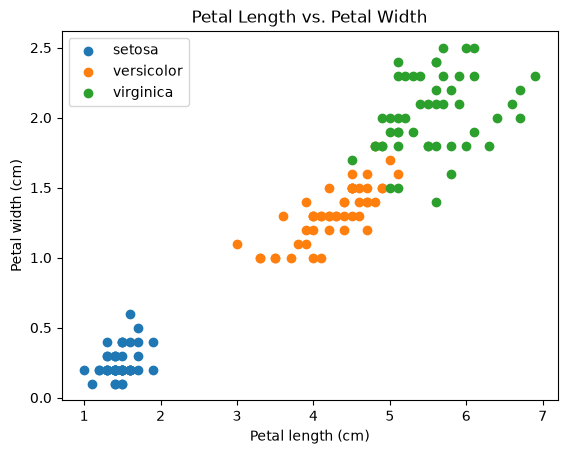

In [4]:
iris = load_iris()

X = np.array(iris.data)
y = np.array(iris.target)

# Project onto petal length and petal width
X_projected = X[:, [2, 3]]

# Visualize the dataset
for i, name in enumerate(iris.target_names):
    plt.scatter(
        X_projected[y == i, 0],
        X_projected[y == i, 1],
        label=name
    )

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Petal Length vs. Petal Width")
plt.legend()

plt.savefig("./media/iris_plot.png", dpi=300, bbox_inches="tight")

plt.show()

## Part 3: PCA

PCA axis vectors:
PC1: [ 0.36138659 -0.08452251  0.85667061  0.3582892 ]
PC2: [ 0.65658877  0.73016143 -0.17337266 -0.07548102]
PC3: [-0.58202985  0.59791083  0.07623608  0.54583143]
PC4: [ 0.31548719 -0.3197231  -0.47983899  0.75365743]


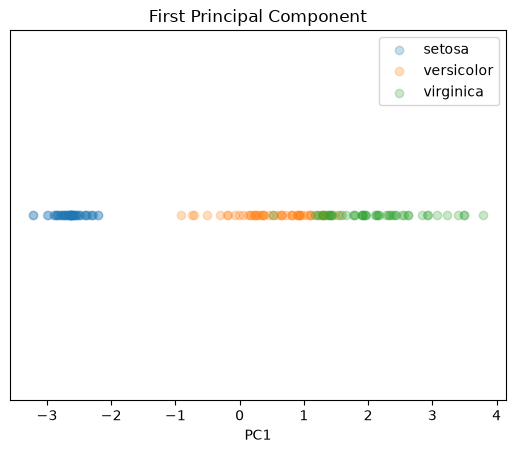

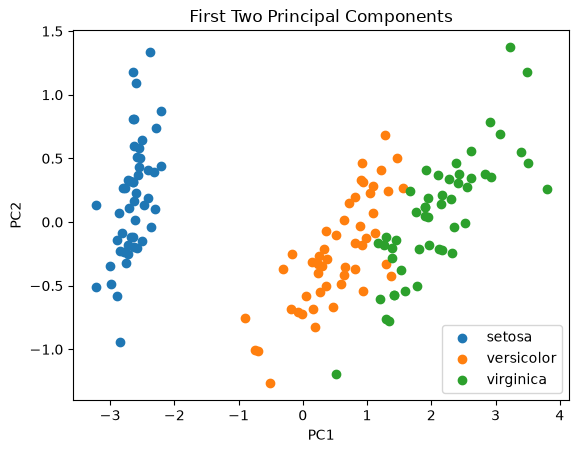

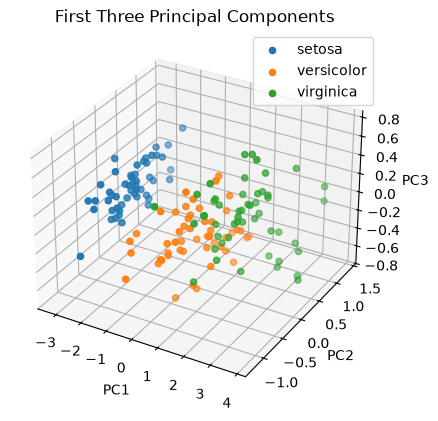

In [15]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
iris = load_iris()
X = np.array(iris.data)
y = np.array(iris.target)

# Perform PCA
pca = PCA(n_components=4)
X_pca = pca.fit_transform(X)

# Print PCA axis vectors
print("PCA axis vectors:")
for i, vector in enumerate(pca.components_):
    print(f"PC{i+1}:", vector)

# 1. First principal component
for i, name in enumerate(iris.target_names):
    plt.scatter(
        X_pca[y == i, 0],
        np.zeros(np.sum(y == i)),
        label=name,
        alpha=0.25
    )

plt.xlabel("PC1")
plt.yticks([])
plt.title("First Principal Component")
plt.legend()
plt.savefig("media/pca_1d.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. First two principal components
for i, name in enumerate(iris.target_names):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=name
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("First Two Principal Components")
plt.legend()
plt.savefig("media/pca_2d.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. First three principal components
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

for i, name in enumerate(iris.target_names):
    ax.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        X_pca[y == i, 2],
        label=name
    )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("First Three Principal Components")
ax.legend()
plt.savefig("media/pca_3d.png", dpi=300, bbox_inches="tight")
plt.show()

## Part 4: Data Compression

In [17]:
# Variance explained by each PC
variance = pca.explained_variance_ratio_

print("Variance explained by each PC:")
for i, v in enumerate(variance):
    print(f"PC{i+1}: {v * 100:.2f}%")

print("\nCumulative variance explained:")
for i, v in enumerate(np.cumsum(variance)):
    print(f"First {i+1} PC(s): {v * 100:.2f}%")

Variance explained by each PC:
PC1: 92.46%
PC2: 5.31%
PC3: 1.71%
PC4: 0.52%

Cumulative variance explained:
First 1 PC(s): 92.46%
First 2 PC(s): 97.77%
First 3 PC(s): 99.48%
First 4 PC(s): 100.00%


## Part 5: Non-linear Components

c:\School\SYDE572\.venv\Lib\site-packages\sklearn\manifold\_isomap.py:386: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
c:\School\SYDE572\.venv\Lib\site-packages\scipy\sparse\_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


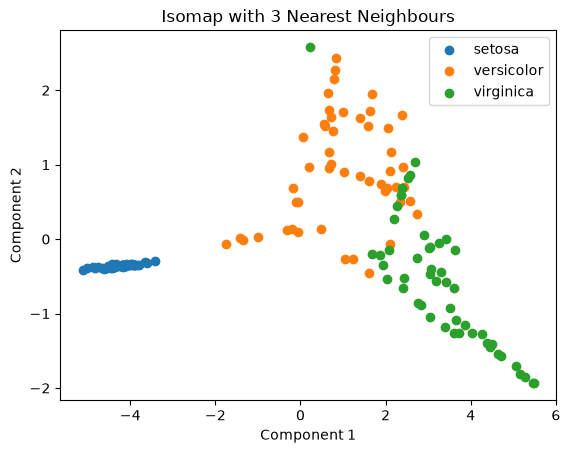

In [27]:

from sklearn.datasets import load_iris
from sklearn.manifold import Isomap
import matplotlib.pyplot as plt
import numpy as np

# Load dataset
iris = load_iris()
X = np.array(iris.data)
y = np.array(iris.target)

# Apply Isomap using 3 nearest neighbours
isomap = Isomap(n_neighbors=3, n_components=2)
X_isomap = isomap.fit_transform(X)

# Plot results
plt.figure()

for i, name in enumerate(iris.target_names):
    plt.scatter(
        X_isomap[y == i, 0],
        X_isomap[y == i, 1],
        label=name
    )

plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("Isomap with 3 Nearest Neighbours")
plt.legend()
plt.savefig("media/isomap_2d.png", dpi=300, bbox_inches="tight")
plt.show()
